# Object Detection Lab 1: Red Blood Cell Detection with YOLOv8

This lab first checks the supplied three-class blood cell dataset, then adapts it
to detect **red blood cells (RBC) only**. The original images and labels are kept.

We use the lab's YOLOv8x model, 5 epochs and image size 480, with NVIDIA GPU 0.
Training and validation run directly in the code cells below.
No training results or accuracy scores have been filled in.

## 1. Setup


Click **Run All** to prepare the data, train, predict and evaluate in order.
Running all cells again starts a new 5-epoch training run.

In [6]:
from pathlib import Path
import shutil

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
import yaml
from IPython.display import display
from ultralytics import YOLO

if torch.cuda.is_available():
    print("GPU is available")
    print("GPU name:", torch.cuda.get_device_name(0))
    print("PyTorch:", torch.__version__, "CUDA:", torch.version.cuda)
    device = 0
else:
    print("GPU is not available. Install the CUDA PyTorch build in README.md.")
    device = "cpu"

assert device == 0, "Choose the Python 3.14 kernel before running this notebook."

GPU is available
GPU name: NVIDIA GeForce RTX 5060 Ti
PyTorch: 2.12.1+cu130 CUDA: 13.0


## 2. Dataset paths and classes

Each image has a matching text file. Each line is
`class_id x_center y_center width height`, with coordinates normalized to 0-1.
Use the existing train, valid and test splits; do not mix test images into training.

The dataset's own `data.yaml` defines **0 = Platelets, 1 = RBC, 2 = WBC**.
The old notebook reversed Platelets and WBC; the order below corrects that.

In [7]:
base_dir = Path.cwd()
if base_dir.name != "YOLO_Object_Detection":
    base_dir = base_dir / "YOLO_Object_Detection"
base_dir = base_dir.resolve()
dataset_dir = base_dir / "dataset" / "blood_cell_dataset"
assert dataset_dir.is_dir(), f"Dataset not found: {dataset_dir}"

with (dataset_dir / "data.yaml").open() as f:
    original_names = yaml.safe_load(f)["names"]
assert original_names == ["Platelets", "RBC", "WBC"]

# RGB colors for the three original classes.
colors = [(0, 200, 0), (255, 0, 255), (255, 140, 0)]
image_extensions = {".jpg", ".jpeg", ".png"}

def image_files(folder):
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in image_extensions)

rows = []
for split in ["train", "valid", "test"]:
    images = image_files(dataset_dir / split / "images")
    labels = list((dataset_dir / split / "labels").glob("*.txt"))
    rows.append({"split": split, "images": len(images), "label files": len(labels)})
display(pd.DataFrame(rows))

,split,images,label files
0,train,765,765
1,valid,73,73
2,test,36,36


## 3. Prepare the original three-class data.yaml

Absolute paths are generated from the current project location, so no Mac paths
are needed. Run this cell again if you move the project.

In [8]:
original_config = {
    "path": dataset_dir.as_posix(),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 3,
    "names": original_names,
}
with (base_dir / "data.yaml").open("w") as f:
    yaml.safe_dump(original_config, f, sort_keys=False)
print((base_dir / "data.yaml").read_text())

path: C:/Users/Pc/Documents/GitHub/AI_class/YOLO_Object_Detection/dataset/blood_cell_dataset
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- Platelets
- RBC
- WBC



## 4. View an image and its ground-truth boxes

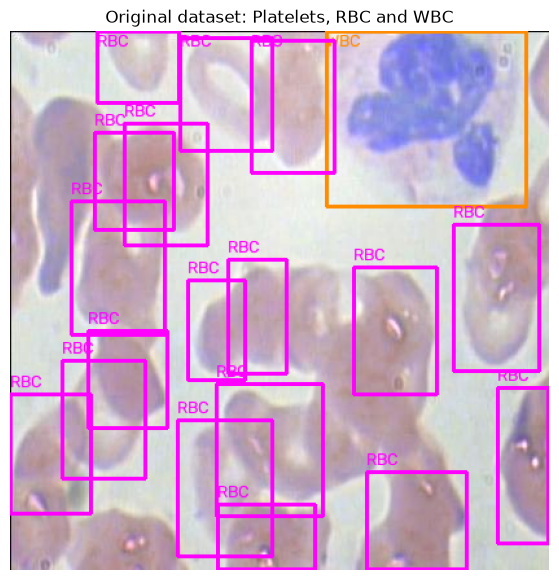

In [9]:
def draw_ground_truth(image_path, label_path, names, box_colors):
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        class_id, xc, yc, bw, bh = map(float, line.split())
        class_id = int(class_id)
        x1, y1 = int((xc - bw / 2) * width), int((yc - bh / 2) * height)
        x2, y2 = int((xc + bw / 2) * width), int((yc + bh / 2) * height)
        color = box_colors[class_id]
        cv2.rectangle(image, (x1, y1), (x2, y2), color, 2)
        cv2.putText(image, names[class_id], (x1, max(y1 - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1)
    return image

example = image_files(dataset_dir / "train" / "images")[0]
label = dataset_dir / "train" / "labels" / (example.stem + ".txt")
plt.figure(figsize=(10, 7))
plt.imshow(draw_ground_truth(example, label, original_names, colors))
plt.title("Original dataset: Platelets, RBC and WBC")
plt.axis("off")
plt.show()

## 5. Custom task: detect RBC only

Copy the images into `dataset/rbc_only`, retain only class 1 (RBC) annotations,
and change their class ID to 0 because the new task has one class.
The original dataset and split assignments stay intact. Images without RBCs
would keep an empty label file as negative examples.

In [10]:
rbc_dir = base_dir / "dataset" / "rbc_only"
rbc_id = original_names.index("RBC")
rows = []
for split in ["train", "valid", "test"]:
    output_images = rbc_dir / split / "images"
    output_labels = rbc_dir / split / "labels"
    output_images.mkdir(parents=True, exist_ok=True)
    output_labels.mkdir(parents=True, exist_ok=True)
    box_count = 0
    images = image_files(dataset_dir / split / "images")
    for image_path in images:
        shutil.copy2(image_path, output_images / image_path.name)
        label_path = dataset_dir / split / "labels" / (image_path.stem + ".txt")
        rbc_lines = []
        for line in label_path.read_text().splitlines():
            parts = line.split()
            if parts and int(parts[0]) == rbc_id:
                rbc_lines.append("0 " + " ".join(parts[1:]))
        (output_labels / label_path.name).write_text("\n".join(rbc_lines) + ("\n" if rbc_lines else ""))
        box_count += len(rbc_lines)
    rows.append({"split": split, "images": len(images), "RBC boxes": box_count})

rbc_config = {
    "path": rbc_dir.as_posix(),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["RBC"],
}
with (base_dir / "data_rbc.yaml").open("w") as f:
    yaml.safe_dump(rbc_config, f, sort_keys=False)
display(pd.DataFrame(rows))
print((base_dir / "data_rbc.yaml").read_text())

,split,images,RBC boxes
0,train,765,8814
1,valid,73,819
2,test,36,398


path: C:/Users/Pc/Documents/GitHub/AI_class/YOLO_Object_Detection/dataset/rbc_only
train: train/images
val: valid/images
test: test/images
nc: 1
names:
- RBC



## 6. Fine-tune YOLOv8



Pretrained YOLOv8x weights download on the first run. Training evaluates the
validation split after each epoch. The best model is saved to
`runs/detect/rbc_yolov8x/weights/best.pt`.

In [11]:
model = YOLO(str(base_dir / "yolov8x.pt"))
train_results = model.train(
    data=str(base_dir / "data_rbc.yaml"),
    epochs=5,
    imgsz=480,
    batch=4,
    device=device,
    workers=0,
    project=str(base_dir / "runs" / "detect"),
    name="rbc_yolov8x",
    exist_ok=True,
)
train_dir = Path(model.trainer.save_dir)
print("Training results saved to:", train_dir)

New https://pypi.org/project/ultralytics/8.4.204 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.90  Python-3.14.6 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\data_rbc.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=480, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\U

## 7. Inspect training results (after your training run)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,41.0222,1.34126,1.27796,1.53745,0.66973,0.79728,0.76725,0.45305,1.32354,1.68962,1.75716,0.000663,0.000663,0.000663
1,2,81.4218,1.30681,1.08283,1.55685,0.72270,0.78510,0.83255,0.56654,1.14663,1.00593,1.58919,0.001067,0.001067,0.001067
2,3,121.0620,1.24041,1.01477,1.51846,0.70351,0.73878,0.80472,0.55016,1.17217,0.99908,1.61898,0.001206,0.001206,0.001206
3,4,161.7960,1.21286,0.96479,1.49275,0.70836,0.80371,0.84270,0.58869,1.07731,0.87954,1.55997,0.000812,0.000812,0.000812
4,5,200.9650,1.17884,0.92895,1.45468,0.75538,0.82784,0.85873,0.59453,1.08158,0.80930,1.55683,0.000416,0.000416,0.000416


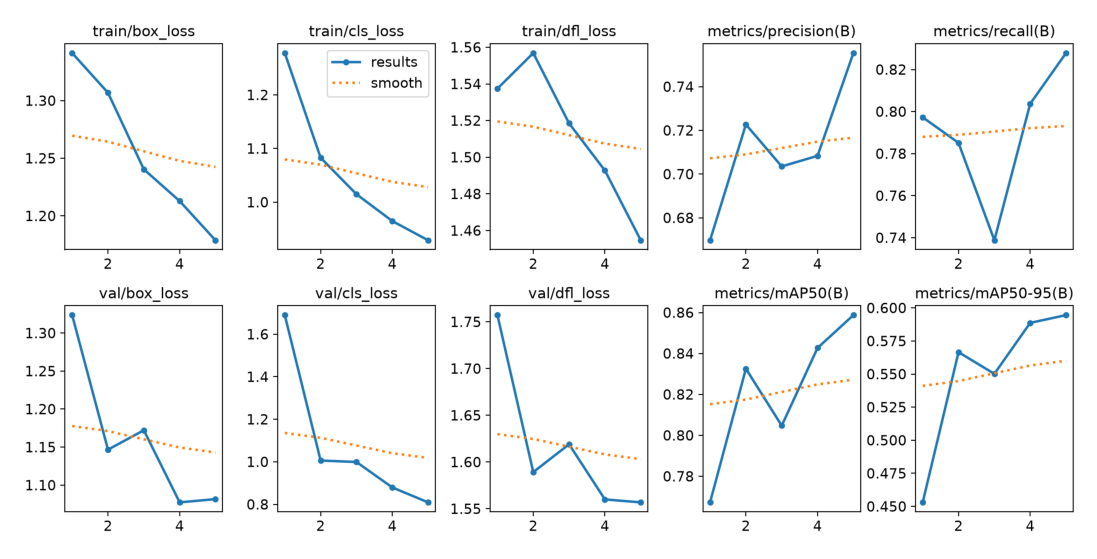

In [12]:
train_dir = base_dir / "runs" / "detect" / "rbc_yolov8x"
history_path = train_dir / "results.csv"
if history_path.exists():
    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()
    display(history)
    plot_path = train_dir / "results.png"
    if plot_path.exists():
        plt.figure(figsize=(14, 7))
        plt.imshow(plt.imread(plot_path))
        plt.axis("off")
        plt.show()
else:
    print("Run the training cell in section 6, then rerun this cell.")

## 8. Predict objects in test images (after training)

Use the custom RBC checkpoint, not a pretrained COCO model or an old three-class run.
Annotated prediction images are saved to `runs/detect/rbc_predictions`.

In [13]:
best_weights = train_dir / "weights" / "best.pt"
test_images = rbc_dir / "test" / "images"
results = []
if best_weights.exists():
    model = YOLO(str(best_weights))
    results = model.predict(
        source=str(test_images), conf=0.25, imgsz=480, device=device,
        save=True, project=str(base_dir / "runs" / "detect"),
        name="rbc_predictions", exist_ok=True,
    )
    print("Test images predicted:", len(results))
else:
    print("Train the RBC model first using section 6.")


image 1/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\images\BloodImage_00038_jpg.rf.ffa23e4b5b55b523367f332af726eae8.jpg: 480x480 18 RBCs, 19.4ms
image 2/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\images\BloodImage_00044_jpg.rf.e7760375eba4bc20c5746367e2311e18.jpg: 480x480 19 RBCs, 18.9ms
image 3/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\images\BloodImage_00062_jpg.rf.1be1ca0ecdf783798fc10346baaa203e.jpg: 480x480 19 RBCs, 19.3ms
image 4/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\images\BloodImage_00090_jpg.rf.cdbf8f6ed3b93fa902a0bc991132cb40.jpg: 480x480 12 RBCs, 19.5ms
image 5/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\images\BloodImage_00099_jpg.rf.e3c42cd68359527494a53843479dff5c.jpg: 480x480 18 RBCs, 18.9ms
image 6/36 C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detectio

## 9. Compare ground truth and predictions

Compare up to three test images. Check for missed cells, extra detections, and
boxes that do not align with the cell boundaries.

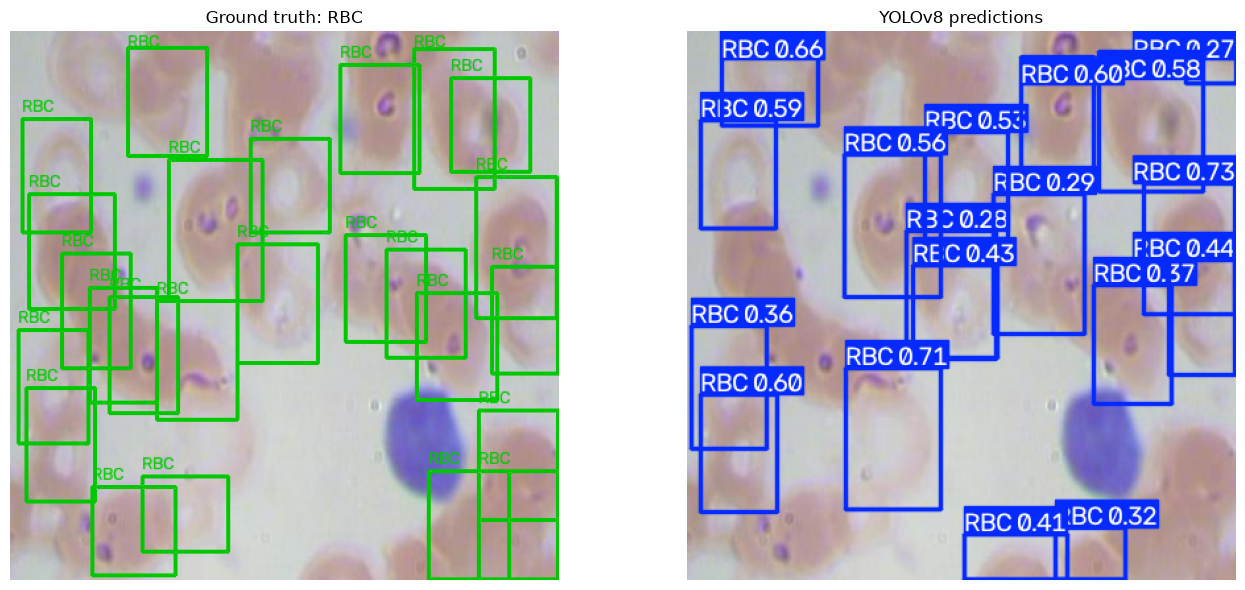

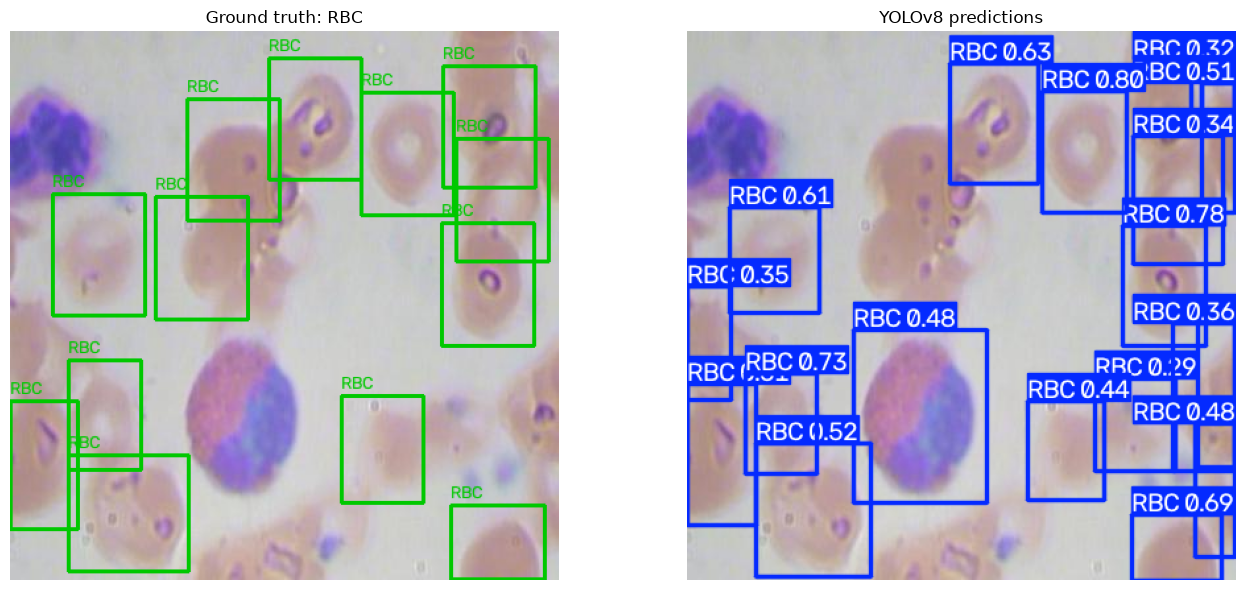

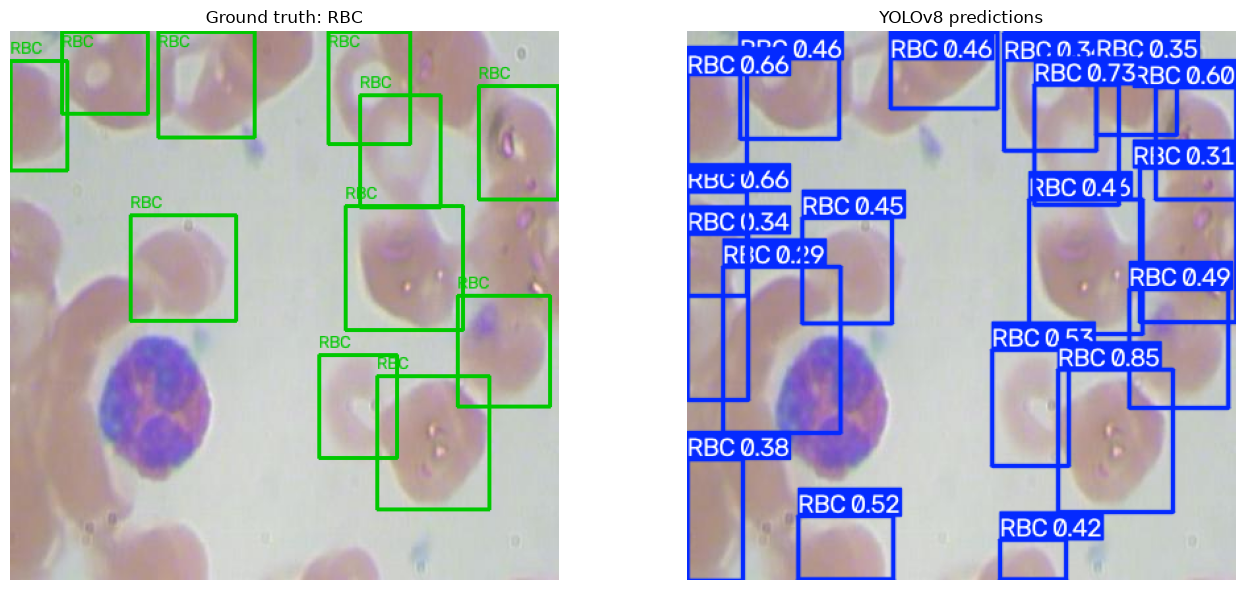

In [14]:
for result in results[:3]:
    image_path = Path(result.path)
    label_path = rbc_dir / "test" / "labels" / (image_path.stem + ".txt")
    truth = draw_ground_truth(image_path, label_path, ["RBC"], [(0, 200, 0)])
    predicted = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(truth)
    axes[0].set_title("Ground truth: RBC")
    axes[1].imshow(predicted)
    axes[1].set_title("YOLOv8 predictions")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 10. IoU and mAP

Intersection over Union (IoU) is the intersection area divided by the union area
of two boxes. The small example below demonstrates the formula; it is not mAP.
Use Ultralytics validation for mAP, which matches boxes by image and class and
accounts for confidence, missed objects and duplicate predictions.

In [15]:
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0.0

print("Example IoU:", calculate_iou([10, 10, 50, 50], [20, 20, 60, 60]))

Example IoU: 0.391304347826087


## 11. Evaluate the trained model

Run the next cell to evaluate the best checkpoint on the held-out **test** split.
It prints precision, recall, mAP50 and mAP50-95, and saves plots to
`runs/detect/rbc_test`.

mAP50 uses IoU 0.50; mAP50-95 averages over IoU thresholds 0.50 to 0.95.
A high score at 0.50 with a lower 0.50-0.95 score can indicate boxes that detect
the correct object but need more precise localization.

In [16]:
test_model = YOLO(str(best_weights))
metrics = test_model.val(
    data=str(base_dir / "data_rbc.yaml"),
    split="test",
    imgsz=480,
    batch=4,
    device=device,
    workers=0,
    plots=True,
    project=str(base_dir / "runs" / "detect"),
    name="rbc_test",
    exist_ok=True,
)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.90  Python-3.14.6 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
Model summary (fused): 113 layers, 68,124,531 parameters, 0 gradients, 257.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 215.453.2 MB/s, size: 12.2 KB)
val: Scanning C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\labels... 36 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 1.3Kit/s 0.0s
val: New cache created: C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\dataset\rbc_only\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 8.6it/s 1.1s0.1s
                   all         36        398      0.712      0.846       0.84       0.59
Speed: 0.3ms preprocess, 18.8ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to C:\Users\Pc\Documents\GitHub\AI_class\YOLO_Object_Detection\runs\detect\rbc_test
Precision: 0.712214888769913
Recall: 0.

## 12. Lab observations 

- **Task modification:** changed the supplied three-class task to RBC-only detection;
  kept class 1 labels and remapped them to class 0 without changing the splits.
- **Hardware:** NVIDIA GeForce RTX 5060 Ti, selected with `device=0`.
- **Training:** YOLOv8x, 5 epochs, image size 480, batch size 4.
- **Test precision / recall / mAP50 / mAP50-95:** record the values from your validation.
- **Visual comparison:** add examples of correctly detected cells, missed cells or extra boxes.
- **Possible improvement:** train for more epochs and compare validation scores;
  keep the test split reserved for the final evaluation.

